**Exploratory Analysis**

In [113]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 


In [65]:
user_engagment = pd.read_csv('takehome_user_engagement.csv')
user_list = pd.read_csv('takehome_users.csv', encoding="utf-8", encoding_errors="replace")

In [66]:
user_engagment.head()

,time_stamp,user_id,visited
0,2014-04-22 03:53:30,1,1
1,2013-11-15 03:45:04,2,1
2,2013-11-29 03:45:04,2,1
3,2013-12-09 03:45:04,2,1
4,2013-12-25 03:45:04,2,1


In [67]:
user_list.head()

,user_id,creation_time,name,email,creation_source,last_session_creation_time,opted_in_to_mailing_list,enabled_for_marketing_drip,org_id,invited_by_user_id
0,1,2014-04-22 03:53:30,Clausen August,AugustCClausen@yahoo.com,GUEST_INVITE,1.398139e+09,1,0,11,10803.0
1,2,2013-11-15 03:45:04,Poole Matthew,MatthewPoole@gustr.com,ORG_INVITE,1.396238e+09,0,0,1,316.0
2,3,2013-03-19 23:14:52,Bottrill Mitchell,MitchellBottrill@gustr.com,ORG_INVITE,1.363735e+09,0,0,94,1525.0
3,4,2013-05-21 08:09:28,Clausen Nicklas,NicklasSClausen@yahoo.com,GUEST_INVITE,1.369210e+09,0,0,1,5151.0
4,5,2013-01-17 10:14:20,Raw Grace,GraceRaw@yahoo.com,GUEST_INVITE,1.358850e+09,0,0,193,5240.0


In [68]:
visits = user_engagment['user_id'].value_counts()

In [69]:
visits

user_id
3623     606
906      600
1811     593
7590     590
8068     585
        ... 
11996      1
11997      1
11998      1
11999      1
12000      1
Name: count, Length: 8823, dtype: int64

In [70]:
user_engagment['time_stamp'] = pd.to_datetime(user_engagment['time_stamp'])
user_engagment['time_stamp'] = (user_engagment['time_stamp'].dt.to_period("W-SUN").dt.start_time.dt.normalize())

In [71]:
user_engagment.groupby('time_stamp')['user_id'].value_counts()

time_stamp  user_id
2012-05-28  8068       1
            10163      1
            2120       1
            1693       1
            9964       1
                      ..
2014-06-02  10212      1
            6070       1
            8760       1
            3203       1
            11599      1
Name: count, Length: 68807, dtype: int64

In [77]:
filtered_users = user_engagment.groupby('time_stamp')['user_id'].value_counts().reset_index(name='count').sort_values(by = 'count', ascending= False)

In [84]:
filtered_users_list = filtered_users.loc[filtered_users['count'] > 2]['user_id'].unique().tolist()

In [85]:
filtered_users_list[:5]

[7210, 7120, 9958, 8068, 2316]

In [87]:
user_list.loc[user_list['user_id'] == 7210]

,user_id,creation_time,name,email,creation_source,last_session_creation_time,opted_in_to_mailing_list,enabled_for_marketing_drip,org_id,invited_by_user_id
7209,7210,2012-08-12 19:17:15,Herzog Benjamin,BenjaminHerzog@gustr.com,ORG_INVITE,1.401909e+09,0,1,243,7210.0


In [88]:
user_list.loc[user_list['user_id'] == 7120]

,user_id,creation_time,name,email,creation_source,last_session_creation_time,opted_in_to_mailing_list,enabled_for_marketing_drip,org_id,invited_by_user_id
7119,7120,2012-07-05 11:44:24,Jessen Sebastian,SebastianAJessen@gmail.com,SIGNUP,1.401882e+09,0,0,270,NaN


In [89]:
user_list.loc[user_list['user_id'] == 9958]

,user_id,creation_time,name,email,creation_source,last_session_creation_time,opted_in_to_mailing_list,enabled_for_marketing_drip,org_id,invited_by_user_id
9957,9958,2012-10-23 23:55:47,Bowen Robert,RobertBowen@hotmail.com,ORG_INVITE,1.401753e+09,0,0,4,5920.0


In [90]:
user_list.loc[user_list['user_id'] == 8068]

,user_id,creation_time,name,email,creation_source,last_session_creation_time,opted_in_to_mailing_list,enabled_for_marketing_drip,org_id,invited_by_user_id
8067,8068,2012-06-01 20:02:35,McCoy Donna,DonnaBMcCoy@hotmail.com,ORG_INVITE,1.401394e+09,0,1,42,8068.0


In [91]:
user_list.loc[user_list['user_id'] == 2316]

,user_id,creation_time,name,email,creation_source,last_session_creation_time,opted_in_to_mailing_list,enabled_for_marketing_drip,org_id,invited_by_user_id
2315,2316,2012-06-16 16:02:39,Carter Travis,TravisYCarter@gmail.com,ORG_INVITE,1.401898e+09,0,0,368,4489.0


In [96]:
heavy_user_list = user_list[user_list['user_id'].isin(filtered_users_list)] #This is the list of users who are using the product 3 times in any given week period

In [139]:
heavy_user_list

,user_id,creation_time,name,email,creation_source,last_session_creation_time,opted_in_to_mailing_list,enabled_for_marketing_drip,org_id,invited_by_user_id
1,2,2013-11-15 03:45:04,Poole Matthew,MatthewPoole@gustr.com,ORG_INVITE,1.396238e+09,0,0,1,316.0
9,10,2013-01-16 22:08:03,Santos Carla,CarlaFerreiraSantos@gustr.com,ORG_INVITE,1.401833e+09,1,1,318,4143.0
19,20,2014-03-06 11:46:38,Helms Mikayla,lqyvjilf@uhzdq.com,SIGNUP,1.401364e+09,0,0,58,NaN
32,33,2014-03-11 06:29:09,Araujo Jos�,JoseMartinsAraujo@cuvox.de,GUEST_INVITE,1.401518e+09,0,0,401,79.0
41,42,2012-11-11 19:05:07,Pinto Giovanna,GiovannaCunhaPinto@cuvox.de,SIGNUP,1.401045e+09,1,0,235,NaN
...,...,...,...,...,...,...,...,...,...,...
11964,11965,2014-04-25 07:17:35,Storey Lewis,LewisStorey@cuvox.de,GUEST_INVITE,1.400657e+09,0,0,65,11251.0
11966,11967,2014-01-12 08:12:37,Barbosa Pedro,PedroFernandesBarbosa@gmail.com,GUEST_INVITE,1.401524e+09,0,0,15,5688.0
11968,11969,2013-06-01 00:48:14,Dickinson Aidan,AidanDickinson@hotmail.com,GUEST_INVITE,1.401411e+09,1,1,52,6647.0
11974,11975,2013-03-23 11:10:11,Daecher J�rgen,JurgenDaecher@gustr.com,GUEST_INVITE,1.400757e+09,1,0,31,6410.0


In [97]:
heavy_user_list.head()

,user_id,creation_time,name,email,creation_source,last_session_creation_time,opted_in_to_mailing_list,enabled_for_marketing_drip,org_id,invited_by_user_id
1,2,2013-11-15 03:45:04,Poole Matthew,MatthewPoole@gustr.com,ORG_INVITE,1.396238e+09,0,0,1,316.0
9,10,2013-01-16 22:08:03,Santos Carla,CarlaFerreiraSantos@gustr.com,ORG_INVITE,1.401833e+09,1,1,318,4143.0
19,20,2014-03-06 11:46:38,Helms Mikayla,lqyvjilf@uhzdq.com,SIGNUP,1.401364e+09,0,0,58,NaN
32,33,2014-03-11 06:29:09,Araujo Jos�,JoseMartinsAraujo@cuvox.de,GUEST_INVITE,1.401518e+09,0,0,401,79.0
41,42,2012-11-11 19:05:07,Pinto Giovanna,GiovannaCunhaPinto@cuvox.de,SIGNUP,1.401045e+09,1,0,235,NaN


In [100]:
heavy_user_list['invited_by_user_id'].fillna(-1)

1          316.0
9         4143.0
19          -1.0
32          79.0
41          -1.0
          ...   
11964    11251.0
11966     5688.0
11968     6647.0
11974     6410.0
11987       -1.0
Name: invited_by_user_id, Length: 1445, dtype: float64

[Text(0, 0, 'False'), Text(1, 0, 'True')]

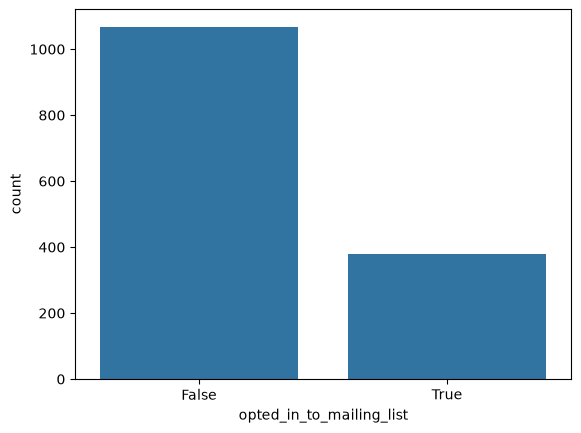

In [153]:
ax = sns.countplot(data = heavy_user_list, x = 'opted_in_to_mailing_list')
ax.set_xticks([0,1])
ax.set_xticklabels(['False','True'])

[Text(0, 0, 'False'), Text(1, 0, 'True')]

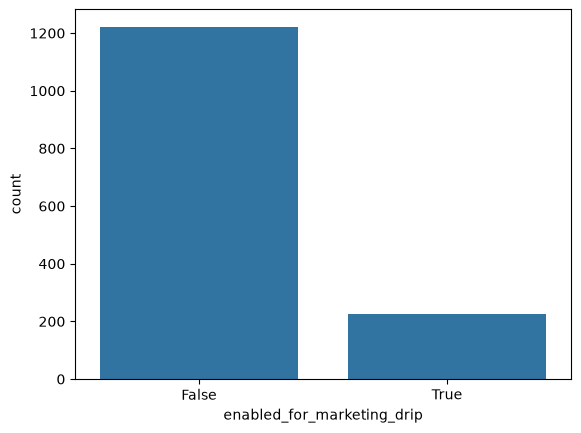

In [154]:
ax = sns.countplot(data = heavy_user_list, x = 'enabled_for_marketing_drip')
ax.set_xticks([0,1])
ax.set_xticklabels(['False','True'])

In [105]:
heavy_user_list['invited_by_user_id'].nunique()

684

In [106]:
heavy_user_list['org_id'].nunique()

396

<Axes: xlabel='invited_by_user_id', ylabel='Count'>

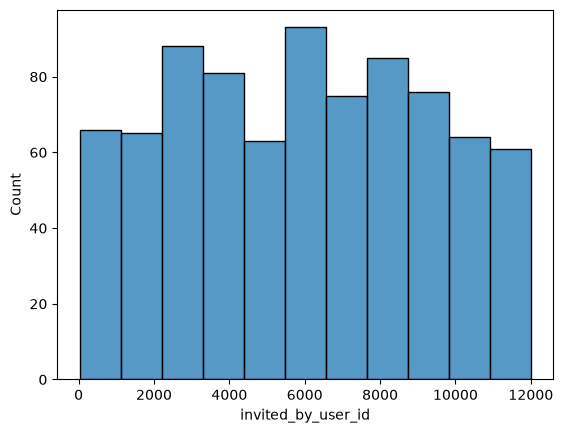

In [104]:
sns.histplot(heavy_user_list, x='invited_by_user_id')

([0, 1, 2, 3, 4],
 [Text(0, 0, 'ORG_INVITE'),
  Text(1, 0, 'SIGNUP'),
  Text(2, 0, 'GUEST_INVITE'),
  Text(3, 0, 'SIGNUP_GOOGLE_AUTH'),
  Text(4, 0, 'PERSONAL_PROJECTS')])

<Figure size 1500x1000 with 0 Axes>

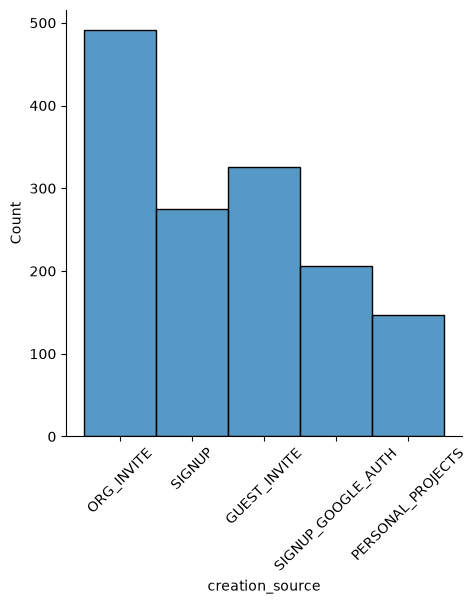

In [118]:
plt.figure(figsize = (15,10))
sns.displot(heavy_user_list,x ='creation_source')
plt.xticks(rotation = 45)

In [119]:
heavy_user_list['org_id'].value_counts(ascending=False)

org_id
7      16
1      14
2      13
9      13
13     13
       ..
397     1
384     1
228     1
339     1
125     1
Name: count, Length: 396, dtype: int64

In [ ]:
heavy_user_list['invited_by_user_id'].value_counts(ascending=False)

invited_by_user_id
2354.0     4
7358.0     3
9726.0     3
10163.0    3
9510.0     3
          ..
1821.0     1
7286.0     1
5093.0     1
2562.0     1
6647.0     1
Name: count, Length: 684, dtype: int64

In [122]:
top_inviters = heavy_user_list['invited_by_user_id'].value_counts()
top_inviters = top_inviters[top_inviters > 1 ].index

result = heavy_user_list[heavy_user_list['invited_by_user_id'].isin(top_inviters)]

In [145]:
result['invited_by_user_id'].value_counts().head(10)

invited_by_user_id
2354.0     4
7358.0     3
9726.0     3
10163.0    3
9510.0     3
10628.0    3
2771.0     3
7882.0     3
4019.0     3
3623.0     3
Name: count, dtype: int64

In [144]:
heavy_user_list['org_id'].value_counts().head(10)

org_id
7     16
1     14
2     13
9     13
13    13
3     13
62    12
5     11
4     11
0     11
Name: count, dtype: int64

In [148]:
heavy_user_list['creation_source'].value_counts()

creation_source
ORG_INVITE            491
GUEST_INVITE          326
SIGNUP                275
SIGNUP_GOOGLE_AUTH    206
PERSONAL_PROJECTS     147
Name: count, dtype: int64

In [127]:
len(heavy_user_list['org_id'])

1445

In [129]:
heavy_user_list['creation_time'] = pd.to_datetime(heavy_user_list['creation_time'])

(array([15522., 15614., 15706., 15796., 15887., 15979., 16071., 16161.]),
 [Text(15522.0, 0, '2012-07'),
  Text(15614.0, 0, '2012-10'),
  Text(15706.0, 0, '2013-01'),
  Text(15796.0, 0, '2013-04'),
  Text(15887.0, 0, '2013-07'),
  Text(15979.0, 0, '2013-10'),
  Text(16071.0, 0, '2014-01'),
  Text(16161.0, 0, '2014-04')])

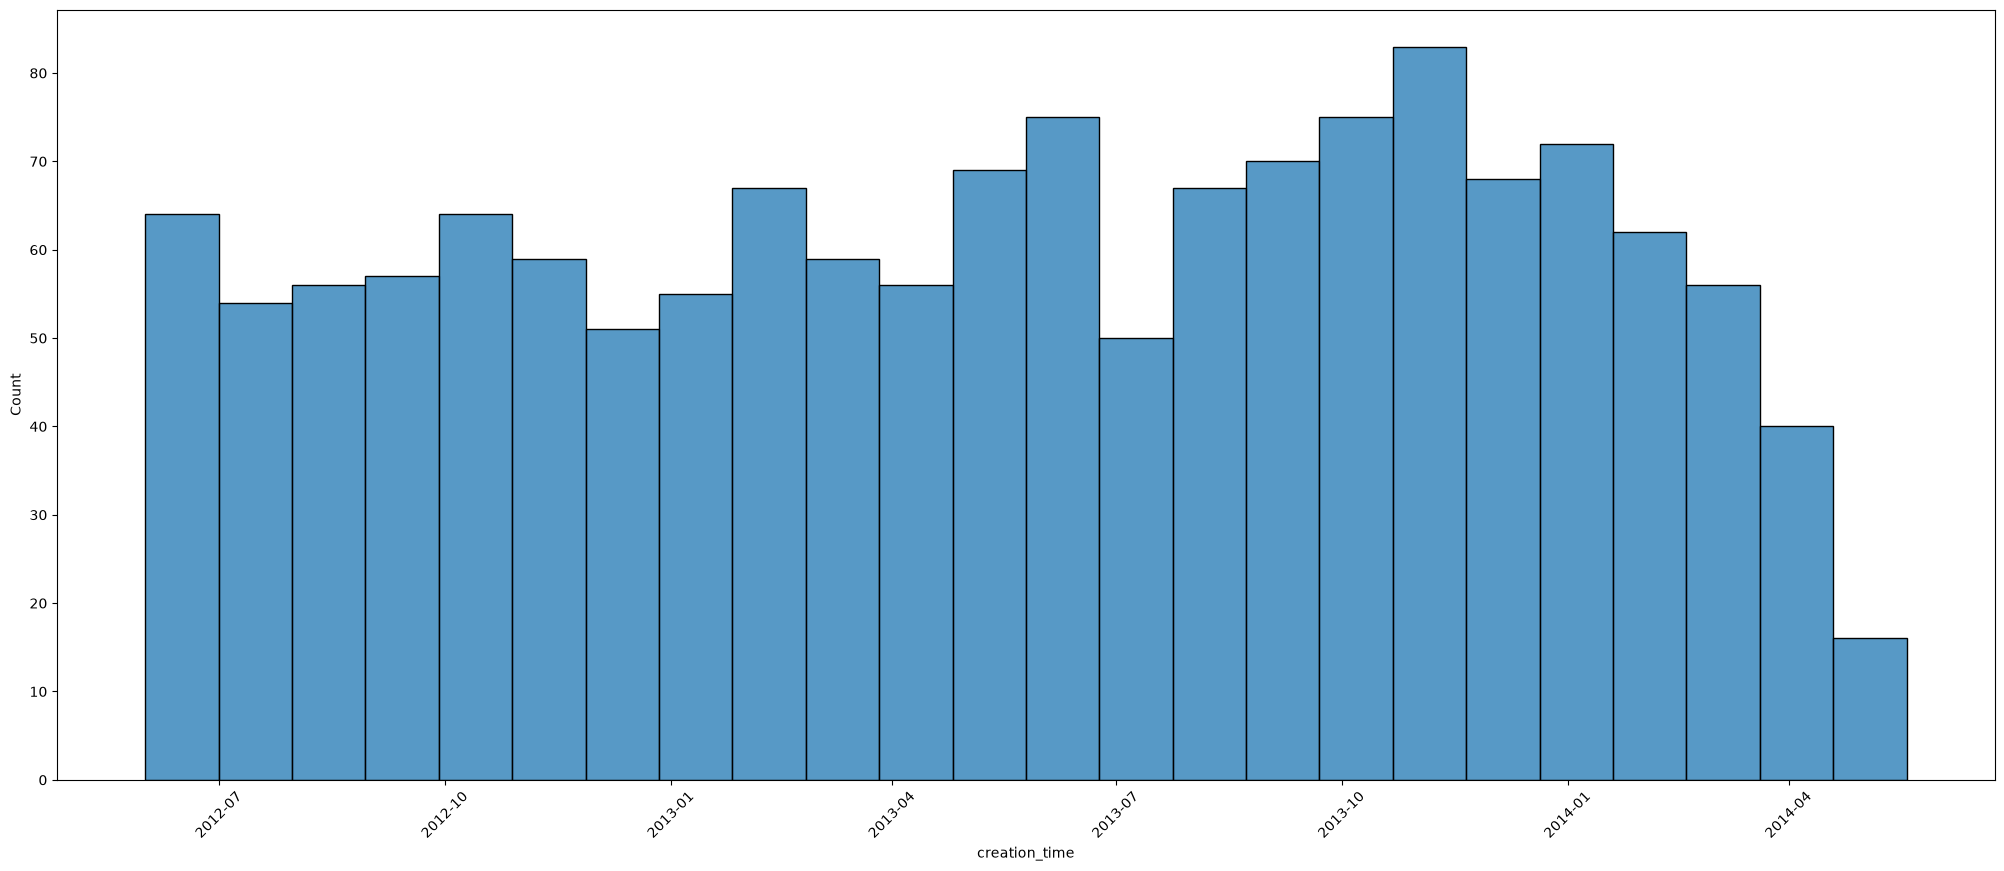

In [155]:
plt.figure(figsize=(25,10))
sns.histplot(heavy_user_list, x = 'creation_time', bins = 24)
plt.xticks(rotation = 45)